# Módulo 1 — Teoría y demostraciones

Notebook de apoyo para la teoría de los **Días 1 y 2** del Módulo 1
(*Python básico para ciencias atmosféricas*). Cada sección trae una
mini-demostración ejecutable de la idea explicada en el
[`README.md`](../README.md) del módulo. No reemplaza la lectura del README:
la complementa con código que se puede correr y modificar.

## Día 1 — Sección 1: tipos de datos y precisión en punto flotante

Python usa `float` de doble precisión (IEEE 754). Esto es relevante para
todo el curso: más adelante vamos a comparar salidas del WRF contra
observaciones, y nunca vamos a comparar dos flotantes con `==`.

In [1]:
a = 0.1 + 0.2
print(f"0.1 + 0.2 = {a}")
print(f"¿0.1 + 0.2 == 0.3? -> {a == 0.3}")

# La forma correcta de comparar floats: con una tolerancia
tolerancia = 1e-9
print(f"¿son 'casi iguales'? -> {abs(a - 0.3) < tolerancia}")

0.1 + 0.2 = 0.30000000000000004
¿0.1 + 0.2 == 0.3? -> False
¿son 'casi iguales'? -> True


## Día 1 — Sección 2: variables como referencias (mutabilidad)

Una variable en Python es una etiqueta que apunta a un objeto. Si el objeto
es mutable (como una lista), modificarlo desde una función afecta al
objeto original, no a una copia.

In [2]:
def agregar_medicion(lista_temperaturas, valor):
    lista_temperaturas.append(valor)  # mutación in-place
    return lista_temperaturas

temperaturas = [18.2, 19.0, 20.1]
resultado = agregar_medicion(temperaturas, 21.5)

print("temperaturas originales:", temperaturas)
print("resultado devuelto:     ", resultado)
print("¿son el mismo objeto? ->", temperaturas is resultado)

temperaturas originales: [18.2, 19.0, 20.1, 21.5]
resultado devuelto:      [18.2, 19.0, 20.1, 21.5]
¿son el mismo objeto? -> True


## Día 1 — Sección 3: listas vs. diccionarios

Una lista se accede por **posición**; un diccionario, por **clave**. Para
datos con significado físico (una estación, una fecha), la clave es casi
siempre más clara y más segura que la posición.

In [3]:
# Acceso por posición: frágil, hay que recordar el orden
temperaturas_lista = [18.2, 19.0, 20.1, 21.5]
print("Día 3 (por posición):", temperaturas_lista[2])

# Acceso por clave: autoexplicativo
temperaturas_dict = {
    "2026-01-01": 18.2,
    "2026-01-02": 19.0,
    "2026-01-03": 20.1,
    "2026-01-04": 21.5,
}
print("Día 3 (por clave):    ", temperaturas_dict["2026-01-03"])

Día 3 (por posición): 20.1
Día 3 (por clave):     20.1


## Día 1 — Sección 4: funciones y alcance (scope)

Una variable definida dentro de una función no existe fuera de ella.

In [4]:
def calcular_promedio(valores):
    suma = 0.0
    for v in valores:
        suma += v
    promedio = suma / len(valores)
    return promedio

print("promedio:", calcular_promedio(temperaturas_lista))

try:
    print(suma)  # 'suma' solo existe dentro de calcular_promedio
except NameError as e:
    print("Error esperado:", e)

promedio: 19.700000000000003
Error esperado: name 'suma' is not defined


## Día 2 — Sección 1: NumPy vs. bucle en Python puro

La misma operación (media, máximo, mínimo, conteo sobre umbral) escrita de
las dos formas, con una medición simple de tiempo para apreciar la
diferencia de forma cualitativa (el resultado exacto depende del equipo,
no hace falta memorizar el número).

In [5]:
import time
import numpy as np

# Números al azar (no son mediciones): aquí solo sirven para medir
# la velocidad con muchos datos. Desde la Sección 3 usamos datos reales.
np.random.seed(0)
datos_grandes = np.random.normal(loc=20, scale=5, size=2_000_000).tolist()

# --- versión con bucle Python puro ---
t0 = time.perf_counter()
suma = 0.0
maximo = datos_grandes[0]
minimo = datos_grandes[0]
conteo_umbral = 0
for v in datos_grandes:
    suma += v
    if v > maximo:
        maximo = v
    if v < minimo:
        minimo = v
    if v > 25:
        conteo_umbral += 1
promedio_bucle = suma / len(datos_grandes)
t_bucle = time.perf_counter() - t0

# --- versión vectorizada con NumPy ---
arr = np.array(datos_grandes)
t0 = time.perf_counter()
promedio_np = arr.mean()
maximo_np = arr.max()
minimo_np = arr.min()
conteo_np = (arr > 25).sum()
t_numpy = time.perf_counter() - t0

print(f"Bucle Python : {t_bucle:.4f} s | promedio={promedio_bucle:.4f}")
print(f"NumPy        : {t_numpy:.4f} s | promedio={promedio_np:.4f}")
print(f"NumPy fue ~{t_bucle / t_numpy:.0f}x más rápido en esta corrida")

Bucle Python : 0.1835 s | promedio=20.0045
NumPy        : 0.0038 s | promedio=20.0045
NumPy fue ~48x más rápido en esta corrida


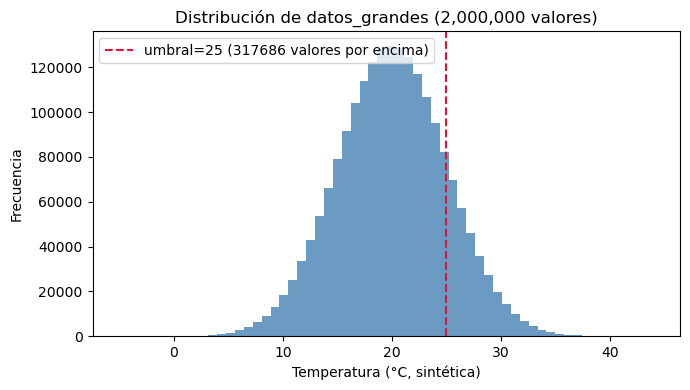

In [6]:
# Adelanto rapido de una figura -- Matplotlib se ve en detalle en la Seccion 5
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(arr, bins=60, color="steelblue", alpha=0.8)
ax.axvline(25, color="crimson", linestyle="--", label=f"umbral=25 ({conteo_np} valores por encima)")
ax.set_xlabel("Temperatura (°C, sintética)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de datos_grandes (2,000,000 valores)")
ax.legend()
fig.tight_layout()
plt.show()

## Día 2 — Sección 2: broadcasting con sentido físico

Sumar un perfil vertical de corrección de temperatura (una dimensión) a una
grilla horizontal replicada en cada nivel (tres dimensiones), sin escribir
ningún bucle explícito.

In [7]:
niveles, lat, lon = 5, 4, 6

# Grilla sintética de temperatura (K), misma temperatura de base + ruido
temperatura_base = 290.0
grilla = temperatura_base + np.random.normal(0, 0.5, size=(niveles, lat, lon))
print("forma de la grilla (niveles, lat, lon):", grilla.shape)

# Perfil vertical de corrección: más frío en los niveles más altos
correccion_vertical = np.array([0.0, -1.5, -3.0, -4.5, -6.0])  # forma (niveles,)
print("forma del perfil vertical:", correccion_vertical.shape)

# Broadcasting: (niveles,) se expande a (niveles, 1, 1) para calzar con (niveles, lat, lon)
grilla_corregida = grilla + correccion_vertical[:, np.newaxis, np.newaxis]

print("Temperatura media por nivel ANTES  de corregir:", grilla.mean(axis=(1, 2)).round(2))
print("Temperatura media por nivel DESPUÉS de corregir:", grilla_corregida.mean(axis=(1, 2)).round(2))

forma de la grilla (niveles, lat, lon): (5, 4, 6)
forma del perfil vertical: (5,)
Temperatura media por nivel ANTES  de corregir: [289.97 290.05 290.01 289.94 289.9 ]
Temperatura media por nivel DESPUÉS de corregir: [289.97 288.55 287.01 285.44 283.9 ]


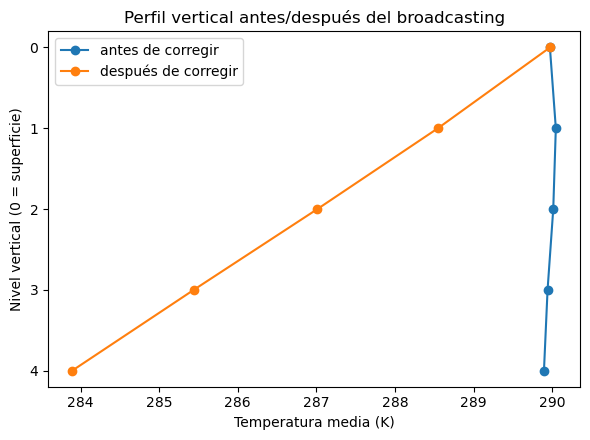

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
niveles_idx = np.arange(niveles)
ax.plot(grilla.mean(axis=(1, 2)), niveles_idx, "o-", label="antes de corregir")
ax.plot(grilla_corregida.mean(axis=(1, 2)), niveles_idx, "o-", label="después de corregir")
ax.invert_yaxis()  # nivel 0 = superficie, arriba
ax.set_xlabel("Temperatura media (K)")
ax.set_ylabel("Nivel vertical (0 = superficie)")
ax.set_yticks(niveles_idx)
ax.set_title("Perfil vertical antes/después del broadcasting")
ax.legend()
fig.tight_layout()
plt.show()

## Día 2 — Sección 3: primer `DataArray` y `Dataset` de Xarray

Datos **reales**: temperatura cada hora de 5 estaciones automáticas de
SENAMHI en Lima, del 14 al 16 de marzo de 2025. Con Xarray cada eje tiene
nombre y coordenadas, para dejar de recordar de memoria qué eje es cuál.

In [9]:
import xarray as xr
import pandas as pd

# 5 estaciones automáticas reales de SENAMHI en Lima (carpeta data/senamhi)
CARPETA = "../../../data/senamhi/"
archivos = {
    "San Martín de Porres": "112265_2025_03.csv",
    "Campo de Marte":       "112181_2025_03.csv",
    "Von Humboldt":         "472AC278_2025_03.csv",
    "Ceres":                "112278_2025_03.csv",
    "Ñaña":                 "111290_2025_03.csv",
}
estaciones = list(archivos)
tiempo = pd.date_range("2025-03-14", periods=72, freq="h")   # 14 al 16 de marzo, hora local

# Pandas se explica en la Sección 4: por ahora solo lo usamos para leer
def leer_senamhi(archivo, columna="Temperatura (°C)"):
    """Serie horaria (hora local) de una columna de un CSV de SENAMHI."""
    d = pd.read_csv(CARPETA + archivo, sep=";", dtype=str)
    if columna not in d.columns:                   # Ceres no mide humedad
        return pd.Series(dtype=float)
    fechas = pd.to_datetime(d["Año"] + "-" + d["Mes"] + "-" + d["Día"] + " " + d["Hora"])
    valores = pd.to_numeric(d[columna], errors="coerce")   # "S/D" (sin dato) -> NaN
    return pd.Series(valores.values, index=fechas, name=columna)

# .reindex(tiempo): deja solo esas 72 horas; si falta alguna, pone NaN
temp_estaciones = np.column_stack([leer_senamhi(a).reindex(tiempo) for a in archivos.values()])

da_temp = xr.DataArray(
    data=temp_estaciones,
    dims=["tiempo", "estacion"],
    coords={"tiempo": tiempo, "estacion": estaciones},
    attrs={"units": "degC", "long_name": "Temperatura del aire", "source": "SENAMHI"},
)
print(da_temp)

<xarray.DataArray (tiempo: 72, estacion: 5)> Size: 3kB
array([[21.1, 20.8, 21.7, 23. , 22.2],
       [20.5, 20.3, 21.5, 22.8, 22.1],
       [20.1, 20.1, 21.3, 22.5, 21.8],
       [20.1, 20.2, 20.9, 22.1, 21.7],
       [19.9, 20. , 20.6, 21.8, 21.7],
       [20.3, 20.1, 20.3, 21.5, 21.6],
       [20.3, 20.1, 20.3, 21.6, 21.6],
       [20.3, 20.2, 20.5, 21.5, 21.7],
       [20.8, 20.7, 21.7, 22.2, 22.2],
       [21.9, 22.4, 23.8, 24.1, 23.2],
       [23.8, 24.8, 26.1, 25.8, 24.4],
       [25.1, 25.5, 27.6, 27.4, 25.5],
       [26.3, 25.7, 27.9, 28.7, 26.1],
       [26. , 25.6, 27.8, 28.6, 26.6],
       [26.3, 26.1, 28.3, 28.7, 26.4],
       [26.5, 26. , 29.1, 28.3, 26.1],
       [25.3, 24.6, 26.8, 26.9, 25.9],
       [24.4, 23.3, 26. , 26. , 25.2],
       [23.6, 22.5, 24.5, 25.7, 25. ],
       [22.5, 21.4, 22.6, 24.3, 24.2],
...
       [21.5, 20.8, 21. , 23.3, 21.7],
       [21.3, 21. , 20.8, 23.1, 21.8],
       [21.1, 20.4, 20.6, 23. , 21.9],
       [21. , 20. , 21.2, 23.7, 21.9],
     

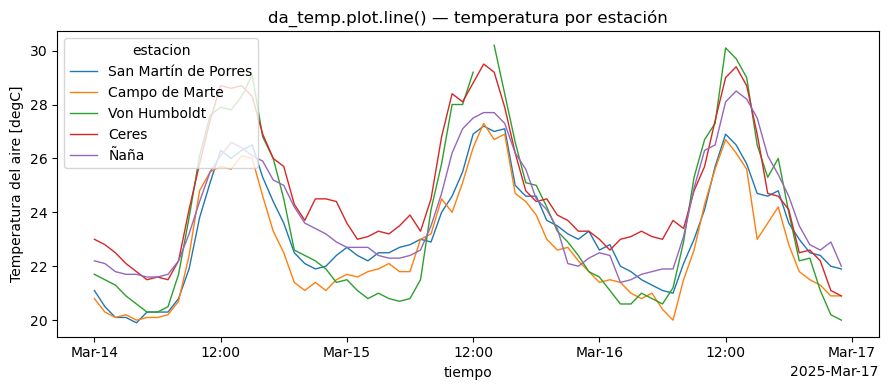

In [10]:
# xarray sabe graficar un DataArray 2D directo con .plot() -- con una
# dimension categorica (estacion) como "hue", dibuja una linea por estacion
fig, ax = plt.subplots(figsize=(9, 4))
da_temp.plot.line(x="tiempo", hue="estacion", ax=ax, linewidth=1)
ax.set_title("da_temp.plot.line() — temperatura por estación")
fig.tight_layout()
plt.show()

In [11]:
# Indexado por NOMBRE (.sel) vs. por POSICIÓN (.isel)
por_nombre = da_temp.sel(estacion="Von Humboldt", tiempo="2025-03-15")
por_posicion = da_temp.isel(estacion=2, tiempo=slice(24, 48))

# Ese día falta el dato de las 13:00 (sale "nan"): es un hueco real del archivo
print("Selección por nombre (Von Humboldt, 2025-03-15), 24 valores:")
print(por_nombre.values.round(2))
print()
print("Selección por posición (índice 2 == Von Humboldt), ¿coincide? ->",
      np.allclose(por_nombre.values, por_posicion.values, equal_nan=True))

Selección por nombre (Von Humboldt, 2025-03-15), 24 valores:
[21.5 21.1 20.8 21.  20.8 20.7 20.8 21.5 24.1 25.8 28.  28.  29.2  nan
 30.2 28.4 26.6 25.1 25.  24.2 23.3 22.9 22.4 21.8]

Selección por posición (índice 2 == Von Humboldt), ¿coincide? -> True


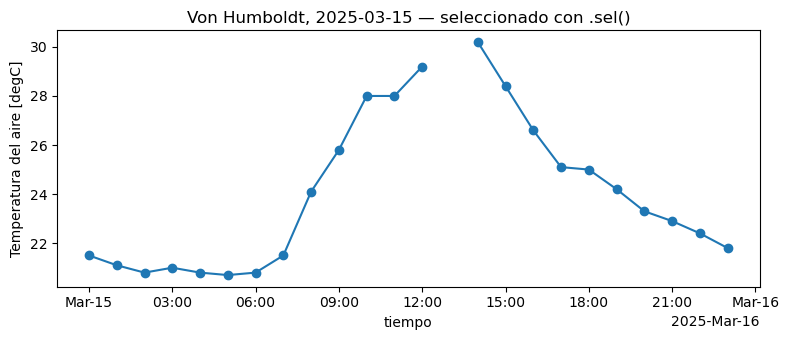

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
por_nombre.plot(ax=ax, marker="o")
ax.set_title("Von Humboldt, 2025-03-15 — seleccionado con .sel()")
fig.tight_layout()
plt.show()

In [13]:
# Un Dataset agrupa varios DataArray que comparten dimensiones
ds = xr.Dataset({"temperatura": da_temp})
ds["humedad"] = xr.DataArray(
    np.column_stack([leer_senamhi(a, "Humedad (%)").reindex(tiempo) for a in archivos.values()]),
    dims=["tiempo", "estacion"],
    attrs={"units": "%", "long_name": "Humedad relativa"},
)
print(ds)

<xarray.Dataset> Size: 7kB
Dimensions:      (tiempo: 72, estacion: 5)
Coordinates:
  * tiempo       (tiempo) datetime64[us] 576B 2025-03-14 ... 2025-03-16T23:00:00
  * estacion     (estacion) <U20 400B 'San Martín de Porres' ... 'Ñaña'
Data variables:
    temperatura  (tiempo, estacion) float64 3kB 21.1 20.8 21.7 ... 20.9 22.0
    humedad      (tiempo, estacion) float64 3kB 100.0 90.0 83.0 ... nan 75.0


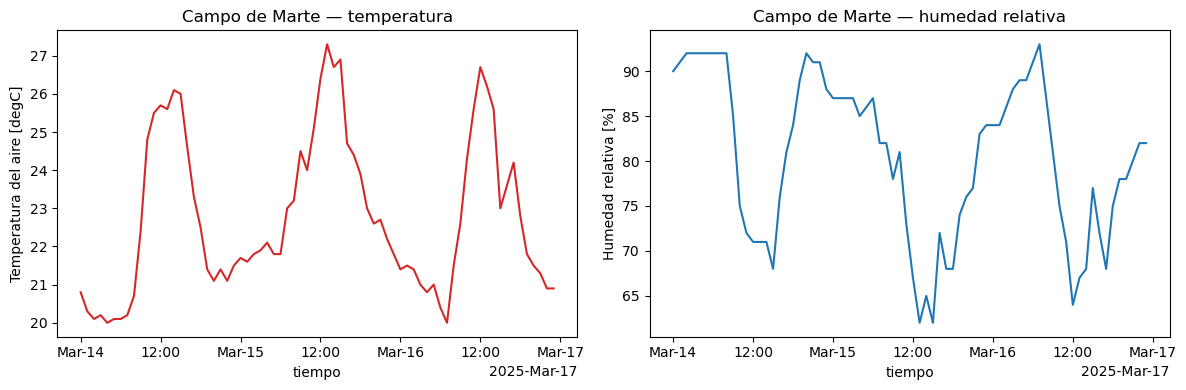

In [14]:
# Otro adelanto: dos paneles con plt.subplots(1, 2, ...) -- se explica
# formalmente en la Seccion 4 de hoy (Matplotlib)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ds["temperatura"].sel(estacion="Campo de Marte").plot(ax=axes[0], color="tab:red")
axes[0].set_title("Campo de Marte — temperatura")
ds["humedad"].sel(estacion="Campo de Marte").plot(ax=axes[1], color="tab:blue")
axes[1].set_title("Campo de Marte — humedad relativa")
fig.tight_layout()
plt.show()

## Día 2 — Sección 4: Pandas para series temporales

`resample` agrega en el tiempo — de horario a diario, por ejemplo — de
forma declarativa gracias al `DatetimeIndex`.

In [15]:
serie_campo = pd.Series(
    data=ds["temperatura"].sel(estacion="Campo de Marte").values,
    index=pd.DatetimeIndex(tiempo, name="tiempo"),
    name="temperatura_campo_de_marte",
)

diaria = serie_campo.resample("1D").mean()
print("Serie horaria (primeras 5 horas):")
print(serie_campo.head())
print()
print("Serie diaria (resampleada):")
print(diaria)

Serie horaria (primeras 5 horas):
tiempo
2025-03-14 00:00:00    20.8
2025-03-14 01:00:00    20.3
2025-03-14 02:00:00    20.1
2025-03-14 03:00:00    20.2
2025-03-14 04:00:00    20.0
Freq: h, Name: temperatura_campo_de_marte, dtype: float64

Serie diaria (resampleada):
tiempo
2025-03-14    22.312500
2025-03-15    23.545833
2025-03-16    22.500000
Freq: D, Name: temperatura_campo_de_marte, dtype: float64


## Día 2 — Sección 5: Matplotlib — el modelo Figure/Axes

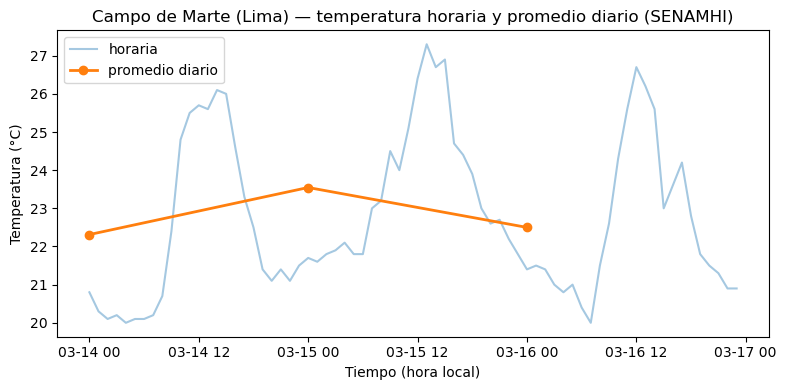

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(serie_campo.index, serie_campo.values, alpha=0.4, label="horaria")
ax.plot(diaria.index, diaria.values, marker="o", linewidth=2, label="promedio diario")
ax.set_xlabel("Tiempo (hora local)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Campo de Marte (Lima) — temperatura horaria y promedio diario (SENAMHI)")
ax.legend()
fig.tight_layout()
plt.show()

---
Fin de la sección de teoría y demos. Continuar con
[`02_practica_dia1.ipynb`](02_practica_dia1.ipynb).